# Naïve Bayes Spam Classifier

Probability is a powerful tool that lets us answer interesting questions about data, and it serves as the foundation of a commonly used machine learning technique for classification We'll also be building a Naïve Bayes classifier from scratch, so you'll get hands-on experience coding a machine learning classifier.

In [3]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import pandas as pd
from sklearn.model_selection import train_test_split
import re
import numpy as np


## Part 1: Data Preparation

The data we will use for this hands-on was put together by Tiago A. Almeida and José María Gómez Hidalgo, and it can be downloaded from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/sms+spam+collection). The data collection process is described in more details [here](http://www.dt.fee.unicamp.br/~tiago/smsspamcollection/#composition).

In [4]:
data = pd.read_csv('data/sms.csv.gz', compression='gzip', sep='\t', header=None, names=['Label', 'SMS'])
data

,Label,SMS
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


### Basic Data Statistics

Compute the fraction of the dataset is ham, and the fraction of the dataset is spam.

In [5]:
frac = data['Label'].value_counts(normalize=True)
print(f"Ham:  {frac['ham']:.4f}")
print(f"Spam: {frac['spam']:.4f}")

Ham:  0.8659
Spam: 0.1341


### Data Cleaning

Let's do some data cleaning: 
1. remove all punctuation
2. make all words lowercase

In [6]:
data['SMS'] = (data['SMS']
               .str.replace(r'[^\w\s]', '', regex=True)
               .str.lower())
data.head()

,Label,SMS
0,ham,go until jurong point crazy available only in ...
1,ham,ok lar joking wif u oni
2,spam,free entry in 2 a wkly comp to win fa cup fina...
3,ham,u dun say so early hor u c already then say
4,ham,nah i dont think he goes to usf he lives aroun...


### Splitting Training and Testing Data

Now, let's split our data into training and testing tests. You can use the `train_test_split` function in scikit-learn to perform this split.

A common split of training and testing data is 80% in the training set, 20% in the test set.

In [7]:
train, test = train_test_split(data, test_size=0.2, random_state=42)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)
print(len(train), len(test))

4457 1115


### Sanity Check the Split

As a little sanity check, let's verify that the percentages of spam and non-spam are roughly equivalent in the training set and the testing set.

In [8]:
print(train['Label'].value_counts(normalize=True))
print(test['Label'].value_counts(normalize=True))

Label
ham     0.865829
spam    0.134171
Name: proportion, dtype: float64
Label
ham     0.866368
spam    0.133632
Name: proportion, dtype: float64


### Build the Vocabulary

A first step to constructing the classifier is to collect the unique set of words that occur in the training data, otherwise known as the **vocabulary**.  Construct a list that contains all unique words. You will need this regardless of whether you build the classifier from scratch or whether you use sklearn.

You may need to do this for both the training and test sets, depending on how you write your code, so you might consider making it a function.

In [9]:
def build_vocabulary(messages):
    return sorted({word for msg in messages for word in msg.split()})

vocabulary = build_vocabulary(train['SMS'])
print(len(vocabulary))

8439


### Word Counts for Each Message

Naïve Bayes (e.g., Multinomial Naïve Bayes) expects a sparse matrix, with word counts for each word for each message. Write a function to transform your training set, and call it on your training and test sets to get word count matrices for each.

In [10]:
def word_count_matrix(messages, vocab):
    index = {w: i for i, w in enumerate(vocab)}
    counts = np.zeros((len(messages), len(vocab)), dtype=np.int32)
    for row, msg in enumerate(messages):
        for word in msg.split():
            j = index.get(word)
            if j is not None:
                counts[row, j] += 1
    return pd.DataFrame(counts, columns=vocab)

X_train_wc = word_count_matrix(train['SMS'], vocabulary)
X_test_wc = word_count_matrix(test['SMS'], vocabulary)
y_train = train['Label']
y_test = test['Label']
X_train_wc.head(5)

,0,008704050406,0089my,0121,01223585236,01223585334,020603,0207,02070836089,02072069400,...,zhong,zindgi,zoe,zogtorius,zoom,zouk,zyada,é,ü,üll
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Part 2: Naïve Bayes Classifier with sklearn

Now that you have your word matrices, counts, and labels for your training and test sets, you can call `sklearn`'s multinomial Naïve Bayes classifier to train and test your model.

1. Train the classifier
2. Count the number of mislabeled points.

In [11]:
from sklearn.naive_bayes import MultinomialNB

clf = MultinomialNB()
clf.fit(X_train_wc, y_train)
pred = clf.predict(X_test_wc)
print("Mislabeled points:", (pred != y_test).sum(), "out of", len(y_test))
print("Accuracy:", (pred == y_test).mean())

Mislabeled points: 14 out of 1115
Accuracy: 0.9874439461883409


### Evaluating the sklearn Model

Accuracy alone can be misleading when classes are imbalanced (about 87% of messages are ham), so we also look at the confusion matrix and the precision, recall, and F1 score for each class. Spam is treated as the positive class.

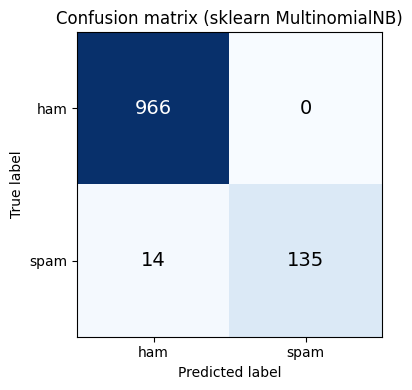

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

labels = ['ham', 'spam']
cm = confusion_matrix(y_test, pred, labels=labels)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(2), labels)
ax.set_yticks(range(2), labels)
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Confusion matrix (sklearn MultinomialNB)')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=14,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.show()

In [24]:
precision, recall, f1, support = precision_recall_fscore_support(y_test, pred, labels=labels)
tn, fp, fn, tp = cm.ravel()

# Spam as the positive class, computed directly from the confusion matrix
spam_precision = tp / (tp + fp)
spam_recall = tp / (tp + fn)
spam_f1 = 2 * spam_precision * spam_recall / (spam_precision + spam_recall)
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"Spam precision: {spam_precision:.4f}")
print(f"Spam recall:    {spam_recall:.4f}")
print(f"Spam F1:        {spam_f1:.4f}")

pd.DataFrame({'precision': precision, 'recall': recall, 'f1': f1, 'support': support}, index=labels)

TN=966  FP=0  FN=14  TP=135
Spam precision: 1.0000
Spam recall:    0.9060
Spam F1:        0.9507


,precision,recall,f1,support
ham,0.985714,1.00000,0.992806,966
spam,1.000000,0.90604,0.950704,149


## Part 3: Naïve Bayes Classifier from Scratch

Although scikit-learn has a Naïve Bayes classifier built-in, we can also implement such a classifier from scratch. In this exercise, you will use labeled SMS messages to classify messages as "spam" or legitimate mail.

In [12]:
from collections import Counter

### Count the Occurrences of Each Word

We now compute how many times each word occurs in each SMS message.

In [13]:
train['counts'] = train['SMS'].apply(lambda m: Counter(m.split()))
train[['Label', 'counts']].head()

,Label,counts
0,spam,"{'reply': 1, 'to': 3, 'win': 1, '100': 1, 'wee..."
1,ham,"{'hello': 1, 'sort': 1, 'of': 1, 'out': 1, 'in..."
2,ham,"{'how': 1, 'come': 1, 'guoyang': 1, 'go': 1, '..."
3,ham,"{'hey': 1, 'sathya': 2, 'till': 1, 'now': 1, '..."
4,spam,"{'orange': 1, 'brings': 1, 'you': 1, 'ringtone..."


## Training the Model

1. Split your data into spam and "ham" (legitimate email).

In [14]:
spam_msgs = train[train['Label'] == 'spam']
ham_msgs = train[train['Label'] == 'ham']
print(len(spam_msgs), len(ham_msgs))

598 3859


2. Calculate the prior probabilities of spam and ham (the prior probabilities for Bayes' Rule.) (Save those values in variables.)

In [15]:
p_spam = len(spam_msgs) / len(train)
p_ham = len(ham_msgs) / len(train)
print(p_spam, p_ham)

0.13417096701817366 0.8658290329818263


3. Caluclate and store:
* the total number of words in spam and 
* the total number of words in ham messages
* the total number of unique words in the training data


In [16]:
spam_counts = Counter()
for c in spam_msgs['counts']:
    spam_counts.update(c)
ham_counts = Counter()
for c in ham_msgs['counts']:
    ham_counts.update(c)

n_spam = sum(spam_counts.values())
n_ham = sum(ham_counts.values())
n_vocab = len(vocabulary)
print(n_spam, n_ham, n_vocab)

14115 54362 8439


4. We now have everything we need to calculate $P(x_i\ |\ y = Spam)$ and $P(x_i\ |\ y = Ham)$ for all words $x_i$ in the vocabulary.  Compute these quantities for each word and store those results in a dictionary. Remember also to adjust these probabilities by some alpha parameter for words that do not appear for some class in the labeled dataset. You should create data structure that have the following quantities for each word:
* the probability that a word appears given that it is spam
* the probability that a word appears given that it is ham


In [17]:
alpha = 1

p_word_spam = {}
p_word_ham = {}
for w in vocabulary:
    p_word_spam[w] = (spam_counts[w] + alpha) / (n_spam + alpha * n_vocab)
    p_word_ham[w] = (ham_counts[w] + alpha) / (n_ham + alpha * n_vocab)

### Classifier

Now define a function `classify` that takes a text message as input and outputs a label, 'spam' or 'ham', given the message.

In [18]:
def clean(message):
    return re.sub(r'[^\w\s]', '', message).lower()

def classify(message):
    p_s, p_h = p_spam, p_ham
    for w in clean(message).split():
        if w in p_word_spam:  # ignore words not seen in training
            p_s *= p_word_spam[w]
            p_h *= p_word_ham[w]
    print('P(Spam|message):', p_s)
    print('P(Ham|message):', p_h)
    print('Label:', 'Spam' if p_s > p_h else 'Ham')

## Testing the Model

### Example Messages
Let's test the spam classifier on a few messages.

In [19]:
classify('Sounds good, Alex, then see u there')

P(Spam|message): 1.150083636635614e-25
P(Ham|message): 5.771278265540065e-21
Label: Ham


In [20]:
classify('YOU WIN THE PRIZE MONEY JACKPOT! CALL 14')

P(Spam|message): 1.1958801682921891e-20
P(Ham|message): 1.8750574069108512e-23
Label: Spam


### Accuracy on Test Set

With obvious spam and non-spam, the classifier seems to be working in the way we would expect. Let's properly evaluate model performance using test data now. We just need to update our function to actual return something first, rather than print

In [21]:
def classify(message):
    # sum of logs avoids underflow on long messages
    log_s, log_h = np.log(p_spam), np.log(p_ham)
    for w in clean(message).split():
        if w in p_word_spam:
            log_s += np.log(p_word_spam[w])
            log_h += np.log(p_word_ham[w])
    return 'spam' if log_s > log_h else 'ham'

In [22]:
preds = test['SMS'].apply(classify)
print("Accuracy:", (preds == test['Label']).mean())
print("Mislabeled points:", (preds != test['Label']).sum(), "out of", len(test))

Accuracy: 0.9874439461883409
Mislabeled points: 14 out of 1115
